In [ ]:
import os
import urllib.request
import matplotlib.pyplot as plt
import kagglehub
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, models

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [ ]:
# Download latest version of the dataset
dataset_path = kagglehub.dataset_download("nirmalsankalana/potato-viral-disease-dataset")
print("Path to dataset files:", dataset_path)
print("Classes available:", os.listdir(dataset_path))

100%|██████████| 799M/799M [00:49<00:00, 17.1MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/nirmalsankalana/potato-viral-disease-dataset/versions/1
Classes available: ['Potato___spindle_tuber_viroid', 'Potato___mosaic_virus', 'Potato___leafroll_virus', 'Potato___healthy']


In [ ]:
# Set parameters
BATCH_SIZE = 32
IMAGE_SIZE = (256, 256)
EPOCHS = 10

# Load Data via image_dataset_from_directory (with validation split)
train_dataset = tf.keras.utils.image_dataset_from_directory(
    dataset_path,
    validation_split=0.2,
    subset="training",
    seed=123,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE
)

val_dataset = tf.keras.utils.image_dataset_from_directory(
    dataset_path,
    validation_split=0.2,
    subset="validation",
    seed=123,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE
)

class_names = train_dataset.class_names
print("Class Names:", class_names)

Found 1413 files belonging to 4 classes.
Using 1131 files for training.
Found 1413 files belonging to 4 classes.
Using 282 files for validation.
Class Names: ['Potato___healthy', 'Potato___leafroll_virus', 'Potato___mosaic_virus', 'Potato___spindle_tuber_viroid']


In [ ]:
# Performance optimization using AUTOTUNE
AUTOTUNE = tf.data.AUTOTUNE
train_dataset = train_dataset.cache().shuffle(1000).prefetch(buffer_size=AUTOTUNE)
val_dataset = val_dataset.cache().prefetch(buffer_size=AUTOTUNE)

In [ ]:
# Model Architecture
data_augmentation = tf.keras.Sequential([
  layers.RandomFlip("horizontal_and_vertical"),
  layers.RandomRotation(0.2),
  layers.RandomZoom(0.2),
])

model = models.Sequential([
    layers.InputLayer(input_shape=(IMAGE_SIZE[0], IMAGE_SIZE[1], 3)),
    layers.Rescaling(1./255),
    data_augmentation,
    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D(),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D(),
    layers.Conv2D(128, (3, 3), activation='relu'),
    layers.MaxPooling2D(),
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(len(class_names), activation='softmax')
])

model.summary()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/input_layer.py:27: UserWarning: Argument `input_shape` is deprecated. Use `shape` instead.
  warnings.warn(


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 256, 256, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 256, 256, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 254, 254, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 127, 127, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 125, 125, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 62, 62, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 60, 60, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 30, 30, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 115200)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    14,745,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,839,492 (56.61 MB)

 Trainable params: 14,839,492 (56.61 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Compile the model
model.compile(
    optimizer='adam',
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=False),
    metrics=['accuracy']
)

# Train the model
history = model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=EPOCHS
)

Epoch 1/10
36/36 ━━━━━━━━━━━━━━━━━━━━ 54s 375ms/step - accuracy: 0.5270 - loss: 1.3737 - val_accuracy: 0.6454 - val_loss: 0.8233
Epoch 2/10
36/36 ━━━━━━━━━━━━━━━━━━━━ 3s 78ms/step - accuracy: 0.7082 - loss: 0.6734 - val_accuracy: 0.7128 - val_loss: 0.5836
Epoch 3/10
36/36 ━━━━━━━━━━━━━━━━━━━━ 3s 76ms/step - accuracy: 0.7790 - loss: 0.5273 - val_accuracy: 0.7908 - val_loss: 0.5592
Epoch 4/10
36/36 ━━━━━━━━━━━━━━━━━━━━ 3s 73ms/step - accuracy: 0.7958 - loss: 0.4649 - val_accuracy: 0.8333 - val_loss: 0.4023
Epoch 5/10
36/36 ━━━━━━━━━━━━━━━━━━━━ 3s 73ms/step - accuracy: 0.8267 - loss: 0.3948 - val_accuracy: 0.8085 - val_loss: 0.4544
Epoch 6/10
36/36 ━━━━━━━━━━━━━━━━━━━━ 3s 73ms/step - accuracy: 0.8444 - loss: 0.3782 - val_accuracy: 0.8617 - val_loss: 0.3566
Epoch 7/10
36/36 ━━━━━━━━━━━━━━━━━━━━ 3s 75ms/step - accuracy: 0.8453 - loss: 0.3817 - val_accuracy: 0.8582 - val_loss: 0.3344
Epoch 8/10
36/36 ━━━━━━━━━━━━━━━━━━━━ 3s 78ms/step - accuracy: 0.8462 - loss: 0.3576 - val_accuracy: 0.8688 -

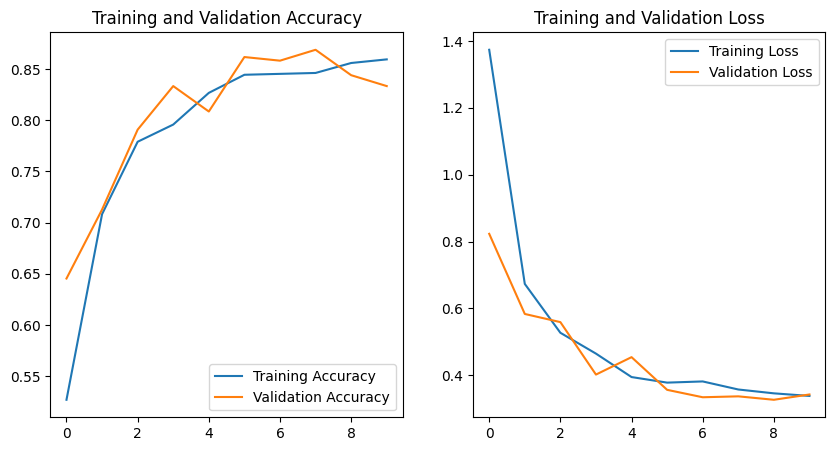

In [ ]:
# Plotting the training results
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']
epochs_range = range(EPOCHS)

plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy')
plt.plot(epochs_range, val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.title('Training and Validation Accuracy')

plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss')
plt.plot(epochs_range, val_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.title('Training and Validation Loss')
plt.show()

In [ ]:
# Save the model
model.save("crop_disease_model.keras")
print("Model saved successfully as crop_disease_model.keras")

Model saved successfully as crop_disease_model.keras


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 353ms/step
This image most likely belongs to Potato___mosaic_virus with a 85.23 percent confidence.


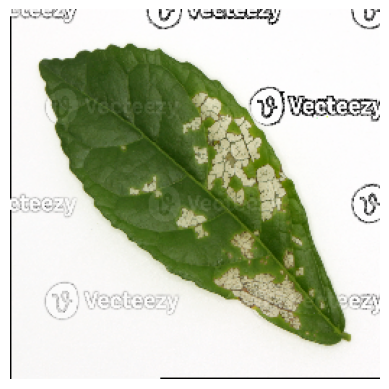

In [ ]:
def predict_image(img_path):
    img = tf.keras.utils.load_img(
        img_path, target_size=IMAGE_SIZE
    )
    img_array = tf.keras.utils.img_to_array(img)
    img_array = tf.expand_dims(img_array, 0) # Create a batch

    predictions = model.predict(img_array)
    score = (predictions[0])

    print("This image most likely belongs to {} with a {:.2f} percent confidence."
        .format(class_names[np.argmax(score)], 100 * np.max(score)))

    plt.imshow(img)
    plt.axis('off')
    plt.show()

# Uncomment and test with your image path:
predict_image("/content/leaf-disease.2.webp")
